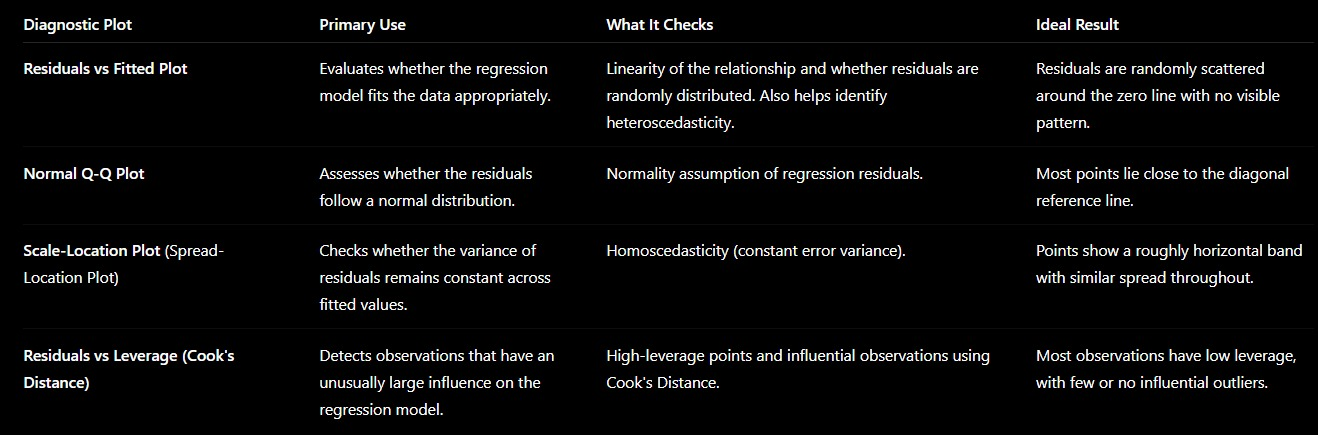

Regression Model : TownCode ~ LATITUDE
                            OLS Regression Results                            
Dep. Variable:               TownCode   R-squared:                       0.949
Model:                            OLS   Adj. R-squared:                  0.949
Method:                 Least Squares   F-statistic:                 1.378e+05
Date:                Sat, 01 Aug 2026   Prob (F-statistic):               0.00
Time:                        14:59:45   Log-Likelihood:                -28293.
No. Observations:                7362   AIC:                         5.659e+04
Df Residuals:                    7360   BIC:                         5.660e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1

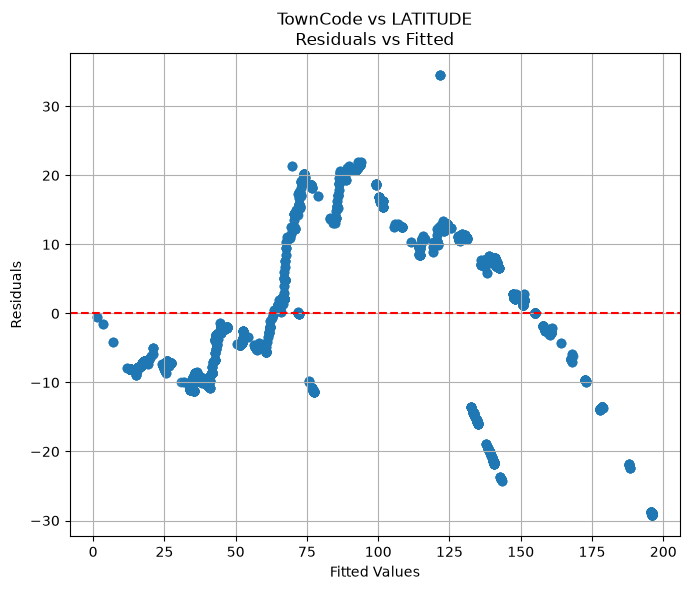

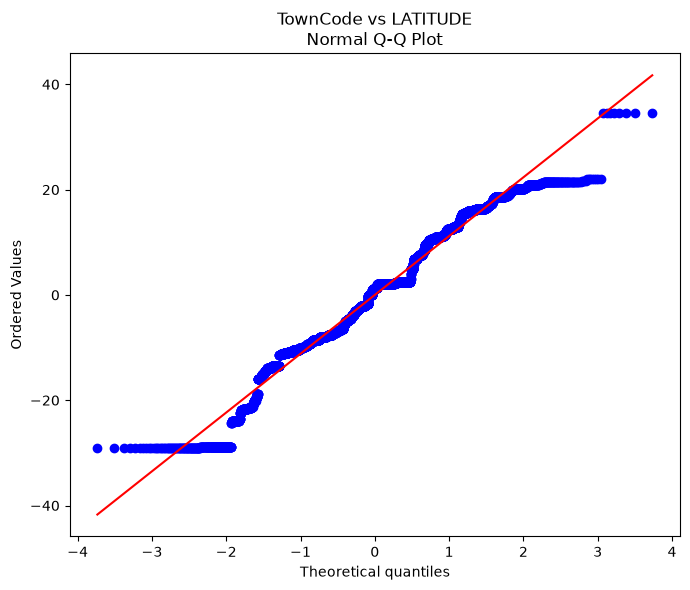

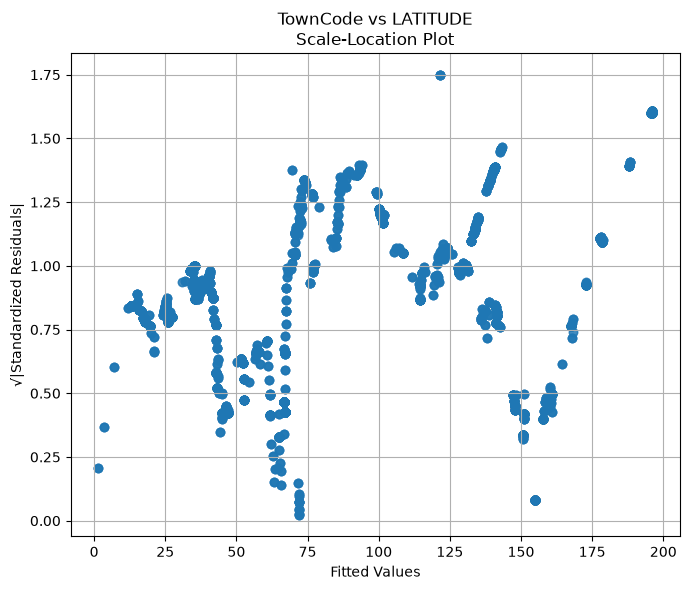

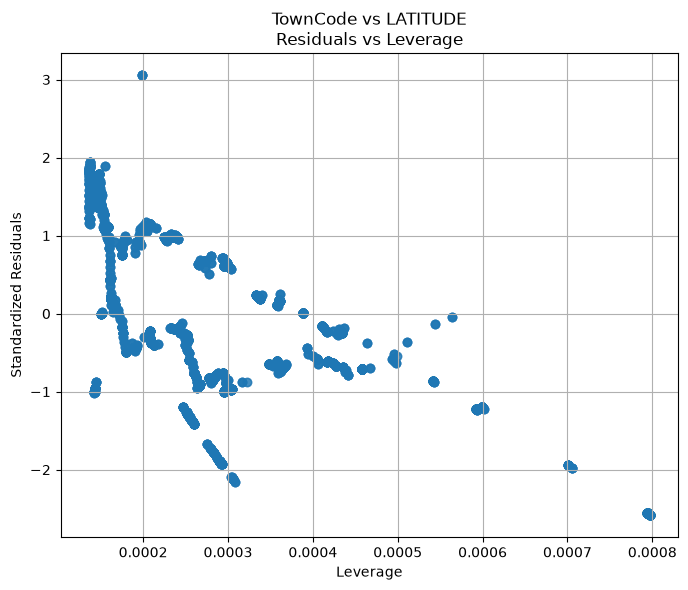

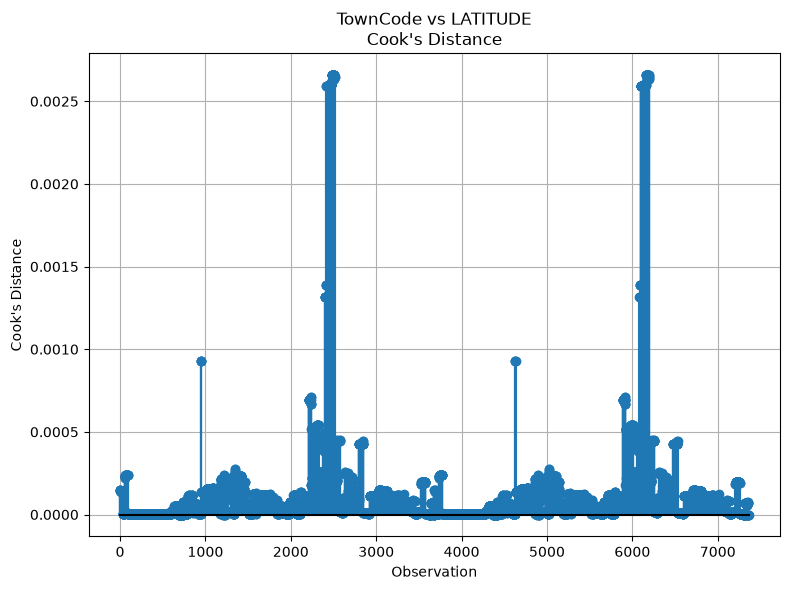

Completed: TownCode ~ LATITUDE


Regression Model : Risk_Level ~ AVG_NOISE_LVL
                            OLS Regression Results                            
Dep. Variable:             Risk_Level   R-squared:                       0.886
Model:                            OLS   Adj. R-squared:                  0.886
Method:                 Least Squares   F-statistic:                 3.004e+04
Date:                Sat, 01 Aug 2026   Prob (F-statistic):               0.00
Time:                        14:59:49   Log-Likelihood:                -730.41
No. Observations:                3874   AIC:                             1465.
Df Residuals:                    3872   BIC:                             1477.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------

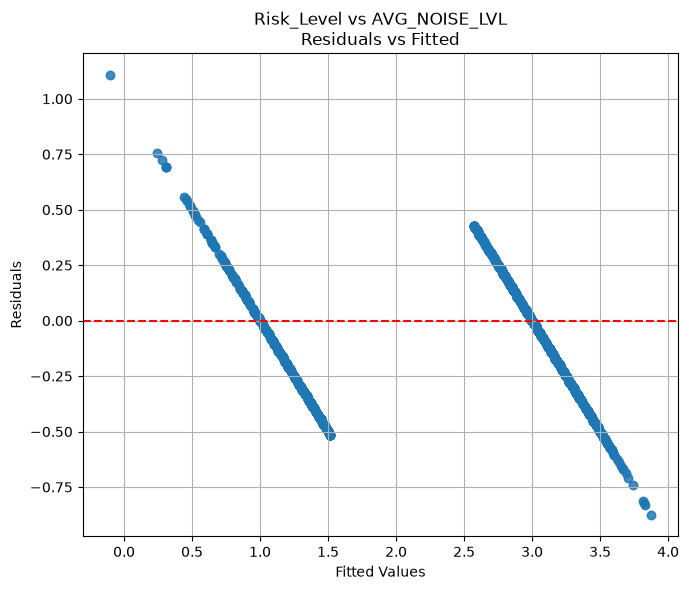

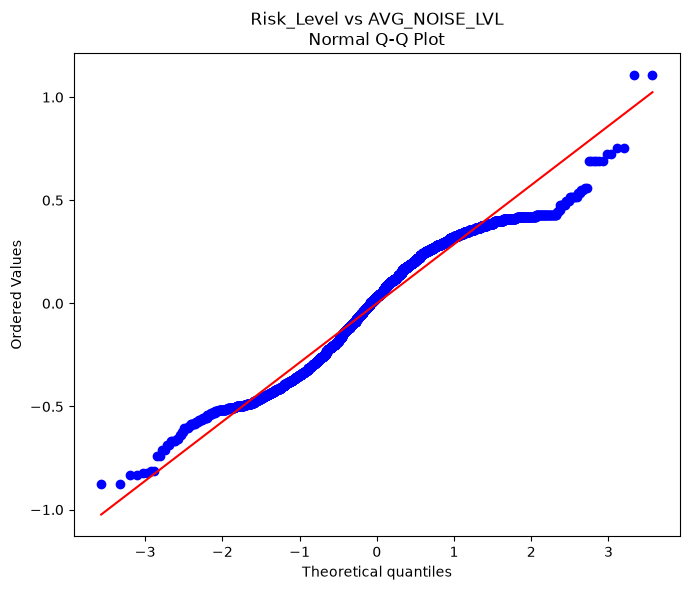

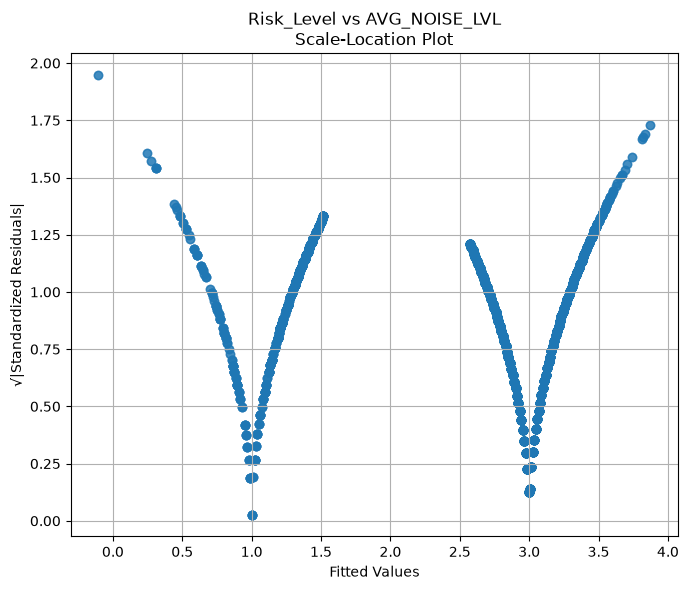

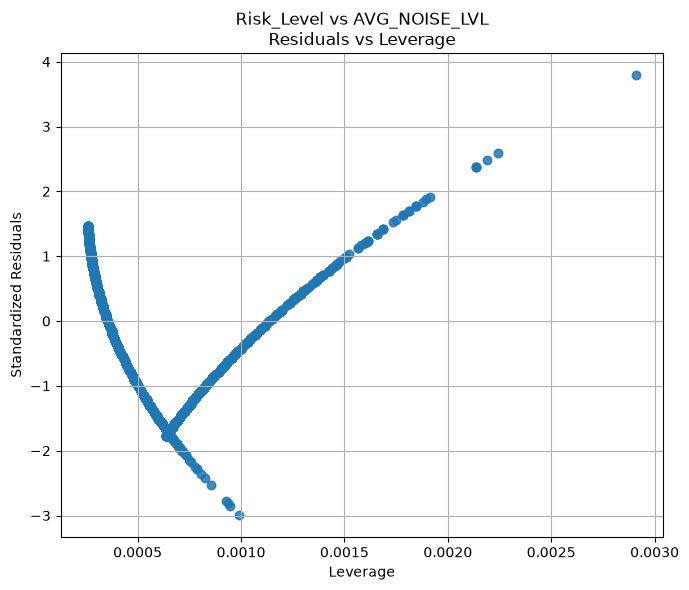

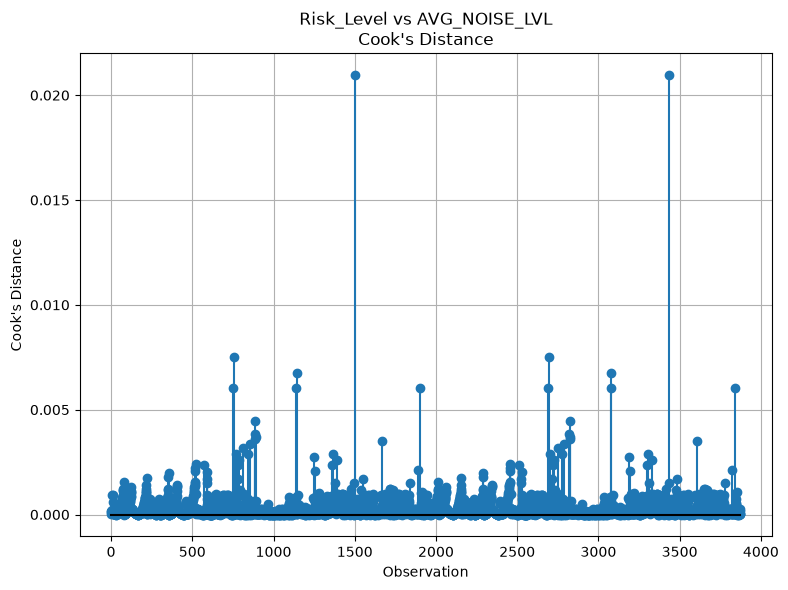

Completed: Risk_Level ~ AVG_NOISE_LVL


Regression Model : Duration_hours ~ AVG_NOISE_LVL
                            OLS Regression Results                            
Dep. Variable:         Duration_hours   R-squared:                       0.015
Model:                            OLS   Adj. R-squared:                  0.015
Method:                 Least Squares   F-statistic:                     111.7
Date:                Sat, 01 Aug 2026   Prob (F-statistic):           6.25e-26
Time:                        14:59:53   Log-Likelihood:                -21232.
No. Observations:                7362   AIC:                         4.247e+04
Df Residuals:                    7360   BIC:                         4.248e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------

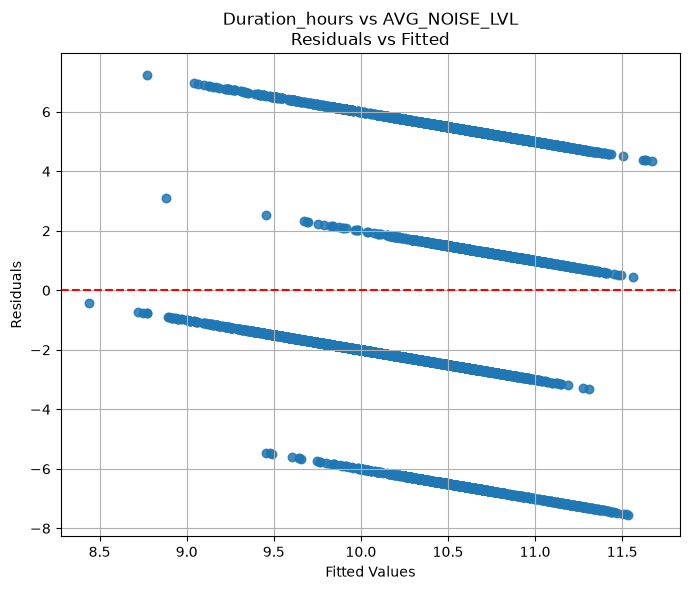

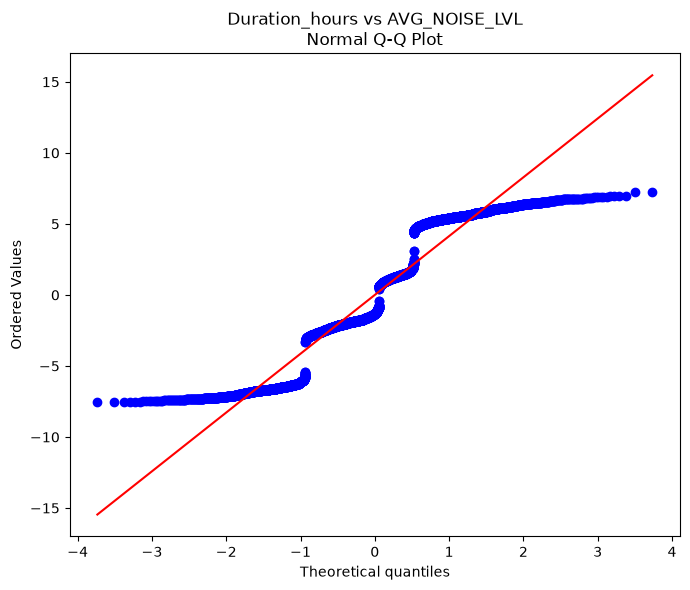

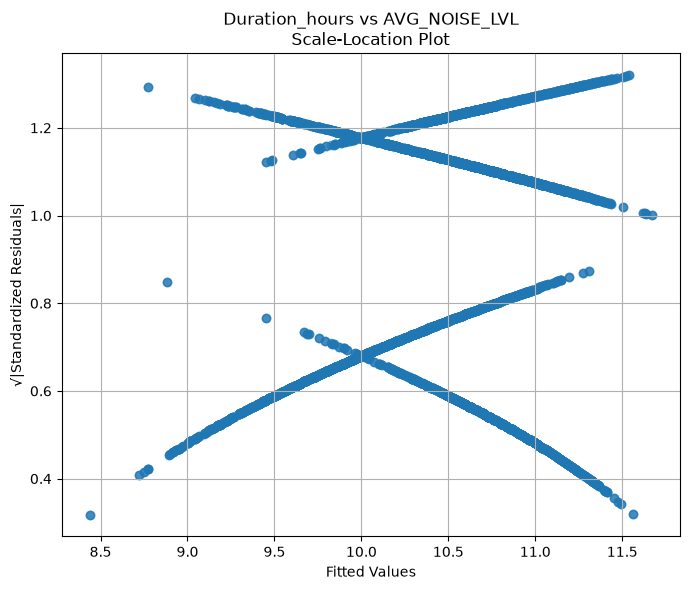

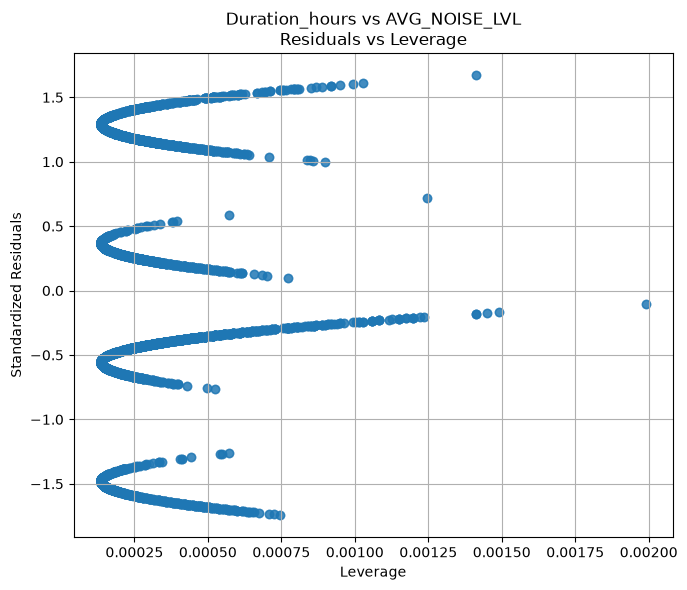

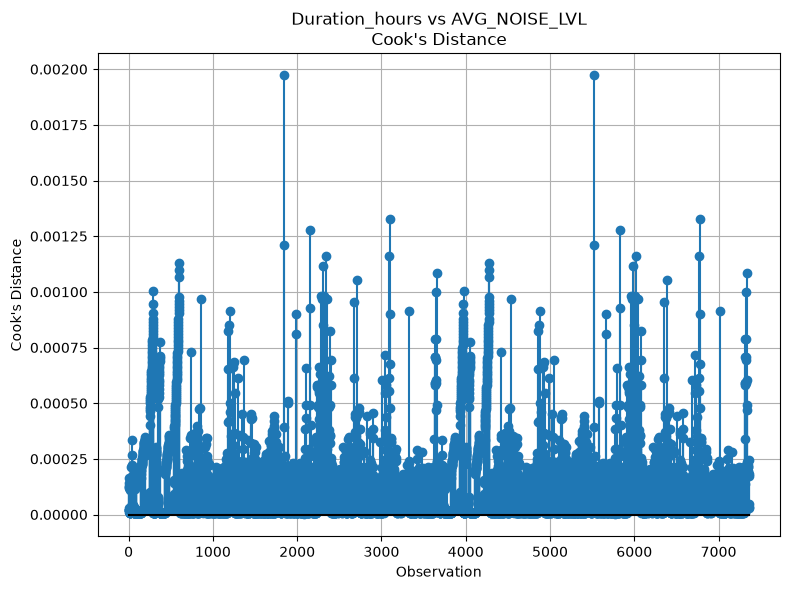

Completed: Duration_hours ~ AVG_NOISE_LVL


Regression Model : Risk_Level ~ Duration_hours
                            OLS Regression Results                            
Dep. Variable:             Risk_Level   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                  0.014
Method:                 Least Squares   F-statistic:                     56.80
Date:                Sat, 01 Aug 2026   Prob (F-statistic):           5.98e-14
Time:                        14:59:58   Log-Likelihood:                -4905.5
No. Observations:                3874   AIC:                             9815.
Df Residuals:                    3872   BIC:                             9828.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------

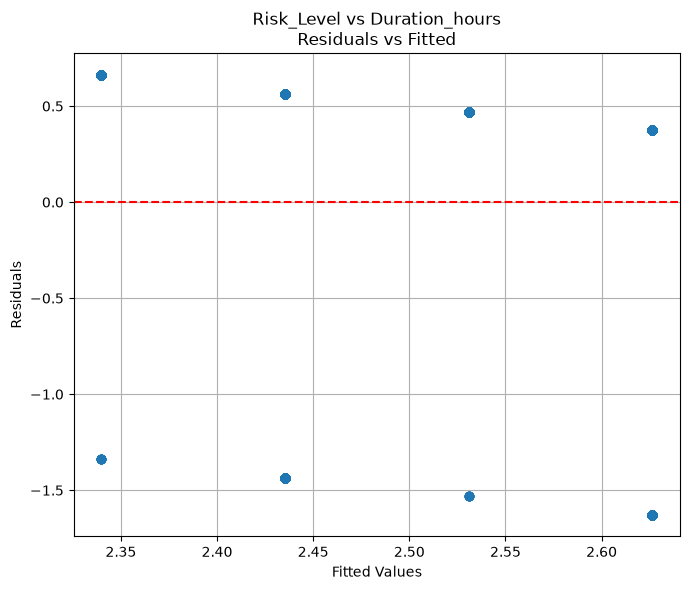

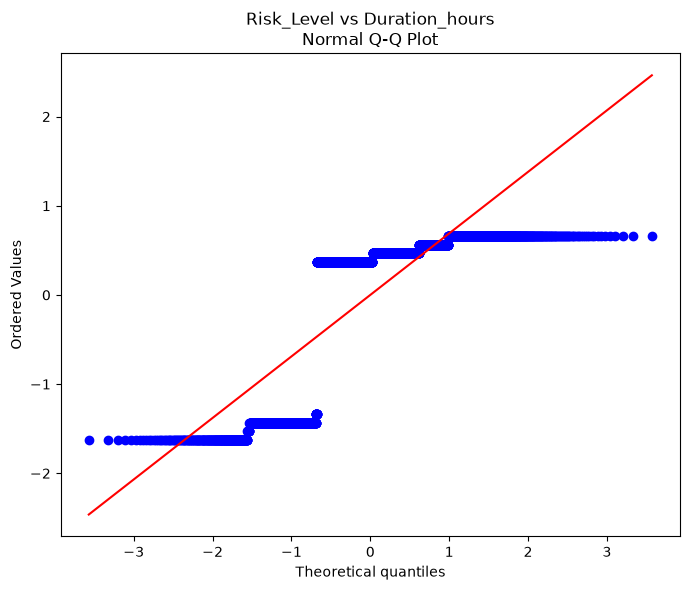

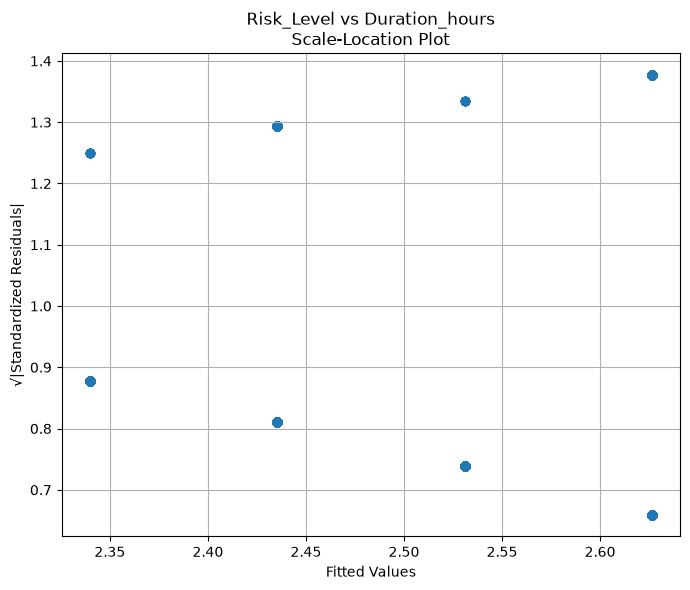

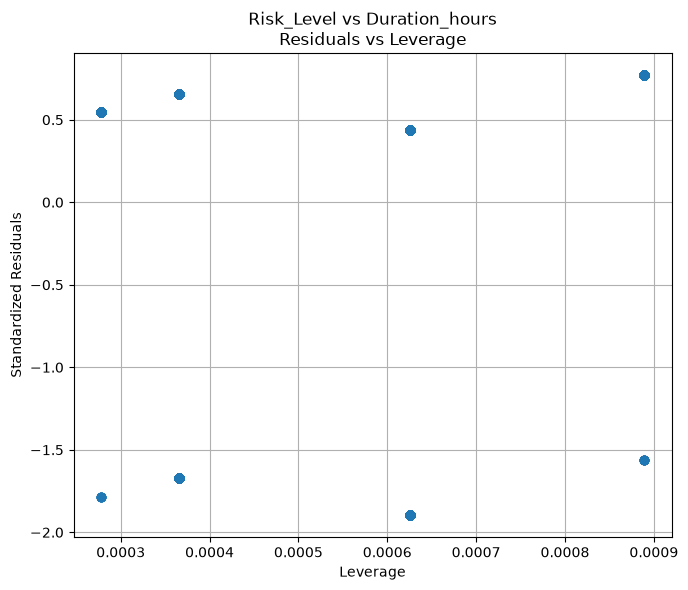

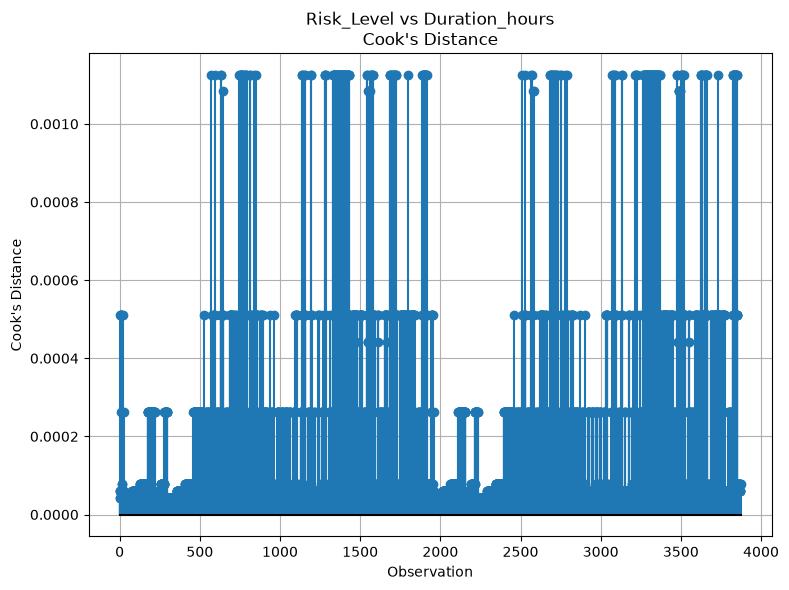

Completed: Risk_Level ~ Duration_hours


Regression Model : Duration_hours ~ LONGITUDE
                            OLS Regression Results                            
Dep. Variable:         Duration_hours   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.002
Method:                 Least Squares   F-statistic:                     12.73
Date:                Sat, 01 Aug 2026   Prob (F-statistic):           0.000362
Time:                        15:00:03   Log-Likelihood:                -21281.
No. Observations:                7362   AIC:                         4.257e+04
Df Residuals:                    7360   BIC:                         4.258e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------

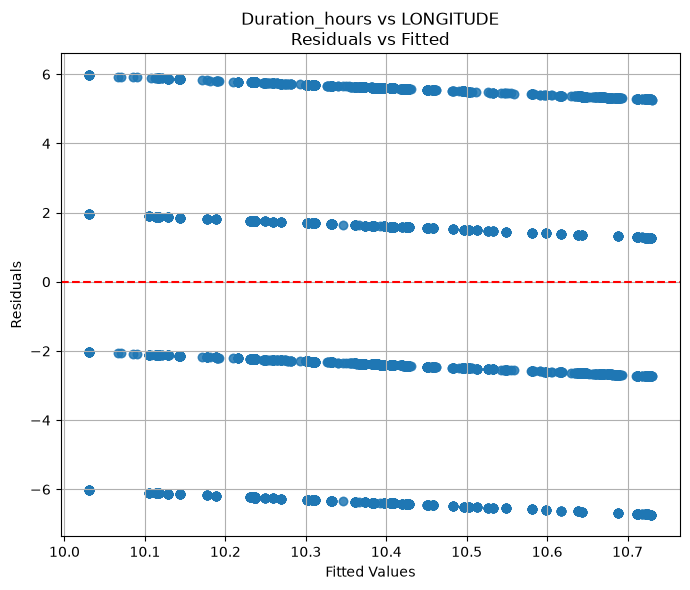

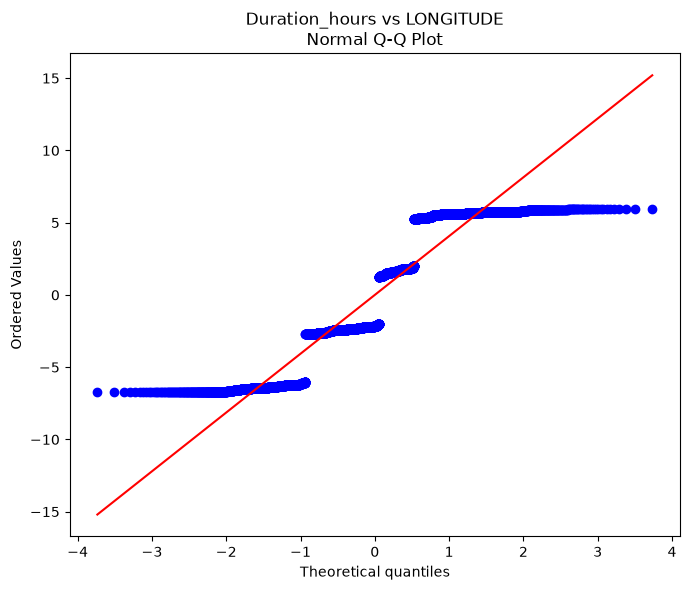

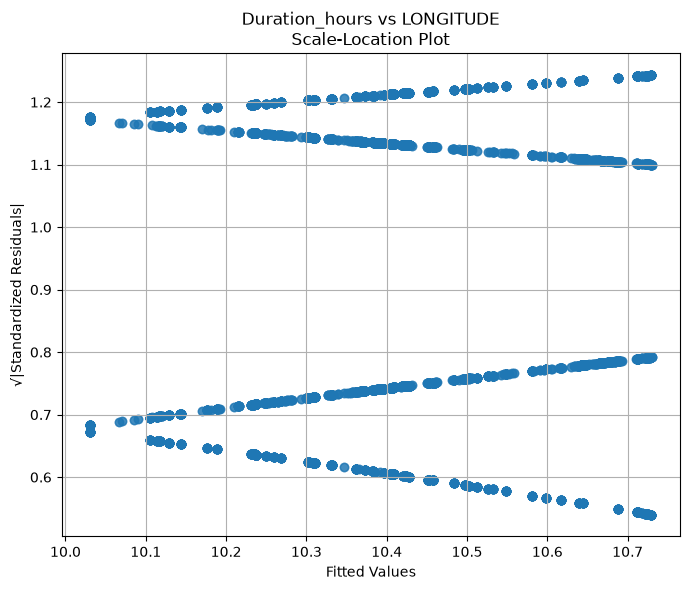

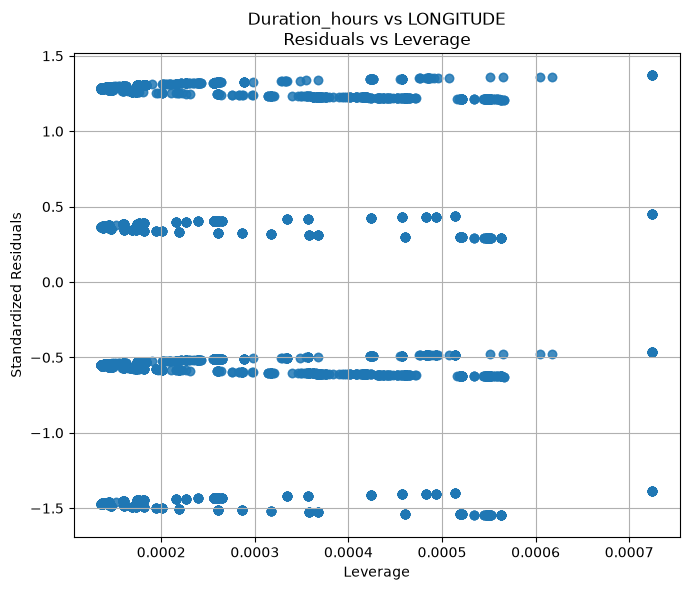

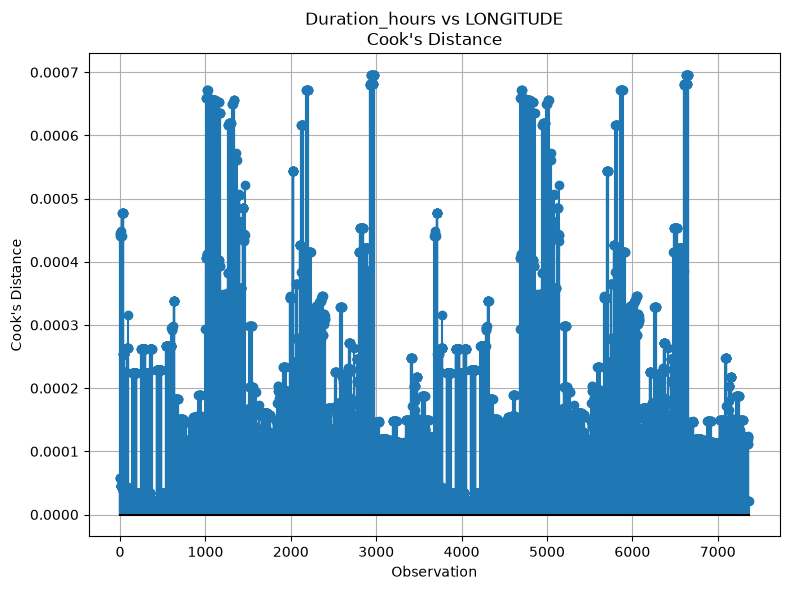

Completed: Duration_hours ~ LONGITUDE


ALL DIAGNOSTIC PLOTS GENERATED SUCCESSFULLY


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm

# ==========================================================
# Load Excel File
# ==========================================================

file_path = r"Road_noise_measurements_filled (1).xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Create TownCode (Latitude -> Longitude)
# ==========================================================

town_locations = (
    df.groupby("TOWN")[["LATITUDE", "LONGITUDE"]]
      .first()
      .reset_index()
)

town_locations = town_locations.sort_values(
    by=["LATITUDE", "LONGITUDE"],
    ascending=[True, True]
).reset_index(drop=True)

town_locations["TownCode"] = range(1, len(town_locations)+1)

df = df.merge(
    town_locations[["TOWN","TownCode"]],
    on="TOWN",
    how="left"
)

# ==========================================================
# Convert Risk Level to Numeric
# ==========================================================

df["Risk_Level"] = (
    df["Risk_Level"]
    .astype(str)
    .str.strip()
    .str.lower()
)

risk_mapping = {
    "low":1,
    "medium":2,
    "high":3
}

df["Risk_Level"] = df["Risk_Level"].map(risk_mapping)

# ==========================================================
# Diagnostic Plot Function
# ==========================================================

def diagnostic_plots(df, x_col, y_col):

    print("="*70)
    print(f"Regression Model : {y_col} ~ {x_col}")
    print("="*70)

    # Select required columns
    data = df[[x_col, y_col]].copy()

    # Convert numeric
    data[x_col] = pd.to_numeric(data[x_col], errors="coerce")
    data[y_col] = pd.to_numeric(data[y_col], errors="coerce")

    # Remove missing values
    data = data.dropna()

    # Regression
    X = sm.add_constant(data[x_col])
    Y = data[y_col]

    model = sm.OLS(Y, X).fit()

    print(model.summary())

    fitted = model.fittedvalues
    residuals = model.resid

    influence = model.get_influence()

    standardized = influence.resid_studentized_internal

    leverage = influence.hat_matrix_diag

    cooks = influence.cooks_distance[0]

    # =====================================================
    # Residuals vs Fitted
    # =====================================================

    plt.figure(figsize=(7,6))

    plt.scatter(
        fitted,
        residuals,
        alpha=0.6
    )

    plt.axhline(
        0,
        color="red",
        linestyle="--"
    )

    plt.xlabel("Fitted Values")

    plt.ylabel("Residuals")

    plt.title(f"{y_col} vs {x_col}\nResiduals vs Fitted")

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        f"{y_col}_vs_{x_col}_Residuals_vs_Fitted.png",
        dpi=300
    )

    plt.show()

    # =====================================================
    # Normal QQ Plot
    # =====================================================

    plt.figure(figsize=(7,6))

    stats.probplot(
        residuals,
        dist="norm",
        plot=plt
    )

    plt.title(f"{y_col} vs {x_col}\nNormal Q-Q Plot")

    plt.tight_layout()

    plt.savefig(
        f"{y_col}_vs_{x_col}_QQ_Plot.png",
        dpi=300
    )

    plt.show()

    # =====================================================
    # Scale Location
    # =====================================================

    plt.figure(figsize=(7,6))

    plt.scatter(
        fitted,
        np.sqrt(np.abs(standardized)),
        alpha=0.6
    )

    plt.xlabel("Fitted Values")

    plt.ylabel("√|Standardized Residuals|")

    plt.title(f"{y_col} vs {x_col}\nScale-Location Plot")

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        f"{y_col}_vs_{x_col}_Scale_Location.png",
        dpi=300
    )

    plt.show()

    # =====================================================
    # Residuals vs Leverage
    # =====================================================

    plt.figure(figsize=(7,6))

    plt.scatter(
        leverage,
        standardized,
        alpha=0.6
    )

    plt.xlabel("Leverage")

    plt.ylabel("Standardized Residuals")

    plt.title(f"{y_col} vs {x_col}\nResiduals vs Leverage")

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        f"{y_col}_vs_{x_col}_Residuals_vs_Leverage.png",
        dpi=300
    )

    plt.show()

    # =====================================================
    # Cook's Distance
    # =====================================================

    plt.figure(figsize=(8,6))

    markerline, stemlines, baseline = plt.stem(
        np.arange(len(cooks)),
        cooks,
        linefmt='C0-',
        markerfmt='C0o',
        basefmt='k-'
    )

    plt.xlabel("Observation")

    plt.ylabel("Cook's Distance")

    plt.title(f"{y_col} vs {x_col}\nCook's Distance")

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        f"{y_col}_vs_{x_col}_Cooks_Distance.png",
        dpi=300
    )

    plt.show()

    print("Completed:", y_col, "~", x_col)
    print("\n")


# ==========================================================
# Generate Diagnostic Plots
# ==========================================================

diagnostic_plots(df, "LATITUDE", "TownCode")

diagnostic_plots(df, "AVG_NOISE_LVL", "Risk_Level")

diagnostic_plots(df, "AVG_NOISE_LVL", "Duration_hours")

diagnostic_plots(df, "Duration_hours", "Risk_Level")

diagnostic_plots(df, "LONGITUDE", "Duration_hours")

print("="*70)
print("ALL DIAGNOSTIC PLOTS GENERATED SUCCESSFULLY")
print("="*70)